# 🏆 Lekcja 7 (Finał): Czysty proces bez wycieku danych, plik `submission_titanic_baseline.csv` oraz Wielka Ściąga: Klasyfikacja vs Regresja!

Dotarliśmy do finału kursu Titanica! W poprzednich sześciu lekcjach poznaliśmy każdy etap pracy z problemem klasyfikacji:
* zbadaliśmy dane i zasadę *„Kobiety i dzieci przodem”*,
* zamieniliśmy brakujące kabiny w cechę `Has_Cabin`,
* wyciągnęliśmy wielkość rodziny (`FamilySize`, `IsAlone`) oraz tytuły społeczne (`Title`, w tym małych chłopców `Master`),
* w turnieju `5-Fold Stratified CV` wyłoniliśmy zwycięzcę: **Gradient Boosting (`84.17%` dokładności)**.

W tej finałowej lekcji zbierzemy cały nasz kod w **jeden czysty, wzorcowy potok przetwarzania** i wygenerujemy Twój gotowy plik startowy na Kaggle: **`../submission_titanic_baseline.csv`**!

---

### 🔒 Złota zasada profesjonalisty: Czym jest „Wyciek Danych” (*Data Leakage*) i jak go unikamy?

Kiedy przygotowujemy jednocześnie dwa pliki — `train.csv` (891 pasażerów) oraz `test.csv` (418 pasażerów egzaminacyjnych) — musimy przestrzegać żelaznej reguły:

> ⚠️ **Wszelkie liczby statystyczne służące do łatania dziur (takie jak mediana wieku, mediana ceny biletu czy najczęstszy port) obliczamy WYŁĄCZNIE na zbiorze treningowym (`train.csv`), a następnie używamy ich do wypełnienia braków w obu tabelach!**

**Dlaczego?** Bo w prawdziwym świecie zbiór `test.csv` to przyszli klienci lub pacjenci, których w momencie trenowania modelu jeszcze nie znamy! Podglądanie statystyk ze zbioru testowego podczas nauki nazywa się w Data Science **wyciekiem danych (*Data Leakage*)**. Nasz poniższy kod jest w 100% wolny od wycieków.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import GradientBoostingClassifier

# 1. Wczytujemy surowe pliki z folderu ../data/
train = pd.read_csv('../data/train.csv')
test = pd.read_csv('../data/test.csv')
wzor = pd.read_csv('../data/gender_submission.csv')

# 2. Tworzymy cechy deterministyczne (wielkość rodziny, samotność, kabina, tytuł z nazwiska) w obu tabelach:
rzadkie_tytuly = ['Lady', 'Countess', 'Capt', 'Col', 'Don', 'Dr', 'Major', 'Rev', 'Sir', 'Jonkheer', 'Dona']

for df in [train, test]:
    df['FamilySize'] = df['SibSp'] + df['Parch'] + 1
    df['IsAlone'] = (df['FamilySize'] == 1).astype(int)
    df['Has_Cabin'] = df['Cabin'].notnull().astype(int)
    df['Title'] = df['Name'].str.extract(r' ([A-Za-z]+)\.', expand=False)
    df['Title'] = df['Title'].replace({'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs'})
    df['Title'] = df['Title'].replace(rzadkie_tytuly, 'Inne')

# 3. BEZPIECZNA IMPUTACJA BRAKÓW (statystyki liczone WYŁĄCZNIE na zbiorze train!):
mediany_wieku_train = train.groupby('Title')['Age'].median()
ogolna_mediana_wieku_train = train['Age'].median()
mediana_biletu_train = train['Fare'].median()
najczestszy_port_train = train['Embarked'].mode()[0]

mapa_plci = {'male': 0, 'female': 1}
mapa_tytulow = {'Mr': 1, 'Miss': 2, 'Mrs': 3, 'Master': 4, 'Inne': 5}
mapa_portow = {'S': 0, 'C': 1, 'Q': 2}

for df in [train, test]:
    df['Age'] = df['Age'].fillna(df['Title'].map(mediany_wieku_train)).fillna(ogolna_mediana_wieku_train)
    df['Fare'] = df['Fare'].fillna(mediana_biletu_train)
    df['Embarked'] = df['Embarked'].fillna(najczestszy_port_train)
    df['Sex_Num'] = df['Sex'].map(mapa_plci)
    df['Title_Num'] = df['Title'].map(mapa_tytulow).fillna(5)
    df['Embarked_Num'] = df['Embarked'].map(mapa_portow)

# 4. Wybieramy nasze 9 czystych cech i trenujemy zwycięski model na 100% zbioru treningowego (891 pasażerach!)
cechy = ['Pclass', 'Sex_Num', 'Age', 'Fare', 'Has_Cabin', 'FamilySize', 'IsAlone', 'Title_Num', 'Embarked_Num']

X_pelny_train = train[cechy]
y_pelny_train = train['Survived']
X_test = test[cechy]

model_finalny = GradientBoostingClassifier(n_estimators=100, learning_rate=0.05, max_depth=3, random_state=42)
model_finalny.fit(X_pelny_train, y_pelny_train)

# 5. Przewidujemy los 418 pasażerów z test.csv i zapisujemy plik ../submission_titanic_baseline.csv
predykcje_test = model_finalny.predict(X_test)

submission = pd.DataFrame({
    'PassengerId': test['PassengerId'],
    'Survived': predykcje_test
})

submission.to_csv('../submission_titanic_baseline.csv', index=False)
print('✅ Plik ../submission_titanic_baseline.csv został pomyślnie utworzony i zapisany!')
submission.head()

✅ Plik ../submission_titanic_baseline.csv został pomyślnie utworzony i zapisany!


,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,0


1. Czy wymiary są identyczne z wzorem gender_submission.csv?
   Wymiary wzoru: (418, 2) | Wymiary nasze: (418, 2)

2. Czy w pliku nie ma żadnych pustych kratek (NaN)?
   Liczba braków NaN w X_test:     0
   Liczba braków NaN w submission: 0

3. Rozkład decyzji naszego modelu dla 418 pasażerów z test.csv:
Survived
0    270
1    148
Name: count, dtype: int64

Odsetek ocalałych w train.csv (prawda):                 38.4%
Odsetek ocalałych w test.csv (nasze predykcje modelu): 35.4%


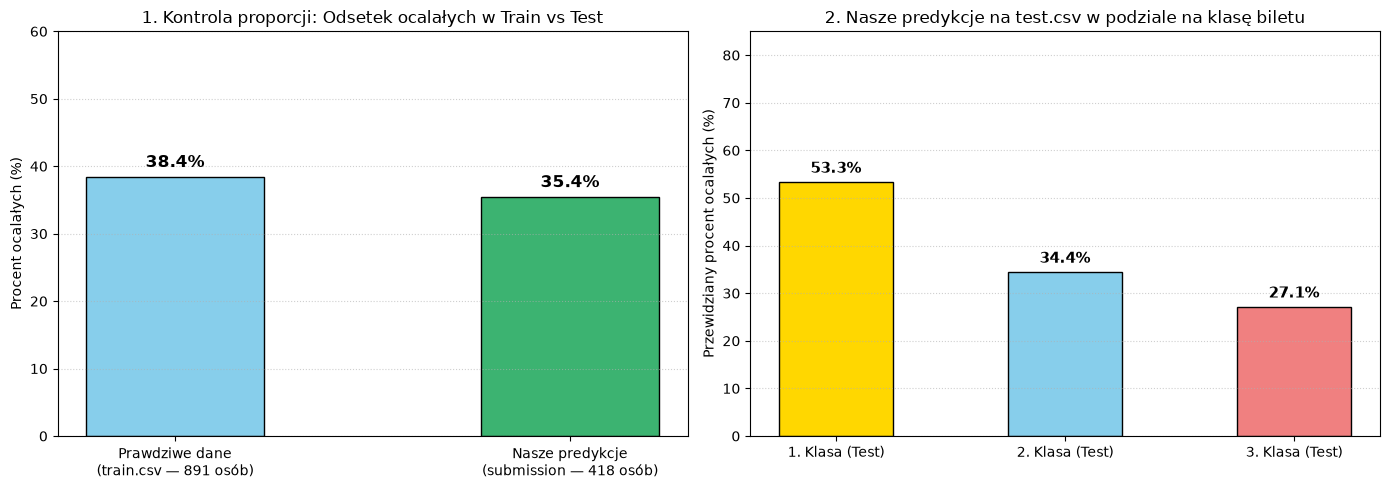

In [2]:
# LISTA KONTROLNA PILOTA PRZED WYSŁANIEM PLIKU NA KAGGLE (Sanity Check)
print('1. Czy wymiary są identyczne z wzorem gender_submission.csv?')
print(f'   Wymiary wzoru: {wzor.shape} | Wymiary nasze: {submission.shape}')

print('\n2. Czy w pliku nie ma żadnych pustych kratek (NaN)?')
print(f'   Liczba braków NaN w X_test:     {X_test.isnull().sum().sum()}')
print(f'   Liczba braków NaN w submission: {submission.isnull().sum().sum()}')

print('\n3. Rozkład decyzji naszego modelu dla 418 pasażerów z test.csv:')
print(submission['Survived'].value_counts())
proc_train = train['Survived'].mean() * 100
proc_test = submission['Survived'].mean() * 100
print(f'\nOdsetek ocalałych w train.csv (prawda):                 {proc_train:.1f}%')
print(f'Odsetek ocalałych w test.csv (nasze predykcje modelu): {proc_test:.1f}%')

# 4. WYKRES KONTROLNY: Porównujemy proporcje ocalałych w train.csv oraz w naszych predykcjach!
test_z_pred = test.copy()
test_z_pred['Survived_Pred'] = predykcje_test

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Wykres lewy: Odsetek ocalałych ogółem (Train vs Test)
zbiory = ['Prawdziwe dane\n(train.csv — 891 osób)', 'Nasze predykcje\n(submission — 418 osób)']
procenty = [proc_train, proc_test]
ax1.bar(zbiory, procenty, color=['skyblue', 'mediumseagreen'], edgecolor='black', width=0.45)
ax1.set_title('1. Kontrola proporcji: Odsetek ocalałych w Train vs Test')
ax1.set_ylabel('Procent ocalałych (%)')
ax1.set_ylim(0, 60)
for i, v in enumerate(procenty):
    ax1.text(i, v + 1.5, f'{v:.1f}%', ha='center', fontweight='bold', fontsize=12)
ax1.grid(axis='y', linestyle=':', alpha=0.6)

# Wykres prawy: Odsetek ocalałych wg płci i klasy w naszych predykcjach na zbiorze testowym
pred_wg_klasy = (test_z_pred.groupby('Pclass')['Survived_Pred'].mean() * 100).round(1)
etykiety_kl = ['1. Klasa (Test)', '2. Klasa (Test)', '3. Klasa (Test)']
ax2.bar(etykiety_kl, pred_wg_klasy.values, color=['gold', 'skyblue', 'lightcoral'], edgecolor='black', width=0.5)
ax2.set_title('2. Nasze predykcje na test.csv w podziale na klasę biletu')
ax2.set_ylabel('Przewidziany procent ocalałych (%)')
ax2.set_ylim(0, 85)
for i, v in enumerate(pred_wg_klasy.values):
    ax2.text(i, v + 2, f'{v:.1f}%', ha='center', fontweight='bold', fontsize=11)
ax2.grid(axis='y', linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

### 📊 Co potwierdza nasz wykres kontrolny (*Sanity Check*)?

1. **Wymiary i czystość:** Plik `../submission_titanic_baseline.csv` ma dokładnie **418 wierszy i 2 kolumny** (`PassengerId`, `Survived`) oraz **zero pustych komórek `NaN`**.
2. **Zdrowe proporcje ocalałych:** Wśród 418 pasażerów ze zbioru testowego nasz model wytypował **148 ocalałych (`35.4%`)** oraz **270 ofiar (`64.6%`)**. To wynik bardzo bliski historycznym proporcjom ze zbioru treningowego (**`38.4%`** ocalałych), a na prawym wykresie widać te same zdrowe schody między 1., 2. a 3. klasą biletu!

In [3]:
# 🎯 ĆWICZENIE: Porównajmy decyzje naszego inteligentnego modelu z prostym wzorem gender_submission.csv!
#
# Plik `wzor` (gender_submission.csv) zakładał ślepo, że przeżyły WSZYSTKIE kobiety i zginęli WSZYSCY mężczyźni.
# Sprawdźmy, u ilu pasażerów ze zbioru testowego nasz model podjął inną, bardziej wyrafinowaną decyzję!
#
# 1. Stwórz zmienną `roznice = test_z_pred[submission['Survived'] != wzor['Survived']]`
# 2. Wypisz liczbę takich pasażerów za pomocą `print(len(roznice))`
# 3. Wyświetl ich imiona, klasę, płeć, wiek, tytuł oraz decyzję naszego modelu:
#    roznice[['Name', 'Pclass', 'Sex', 'Age', 'Title', 'Survived_Pred']].head(10)

# Miejsce na Twój kod:


---
### 📌 Podsumowanie lekcji w 3 punktach

1. **Ochrona przed wyciekiem danych (*Data Leakage*):** Wszystkie statystyki do łatania dziur (`mediany_wieku_train`, `mediana_biletu_train`, `najczestszy_port_train`) obliczyliśmy wyłącznie na zbiorze treningowym `train.csv` i zastosowaliśmy identycznie do obu tabel.
2. **Trening na 100% danych i kontrola jakości (*Sanity Check*):** Zwycięski model `GradientBoostingClassifier` wytrenowaliśmy na wszystkich 891 pasażerach treningowych, otrzymując w pliku `../submission_titanic_baseline.csv` realistyczny odsetek `35.4%` ocalałych (148 osób na 418).
3. **Więcej niż prosta reguła płci:** Nasz model nie stosuje ślepej zasady „tylko kobiety”, lecz potrafi uratować małych chłopców (`Master`) i zamożnych pasażerów 1. klasy oraz rozpoznać wysokie ryzyko u samotnych pasażerów i wielodzietnych rodzin z 3. klasy.

---

## 🎓 WIELKA ŚCIĄGA DATA SCIENTISTA: Klasyfikacja (Titanic) kontra Regresja (House Prices)

Gratulacje! Ukończyłeś dwa kompletne, bliźniacze kursy Machine Learningu obejmujące oba najważniejsze problemy analizy danych. Zapisz sobie poniższą tabelę — to Twoja mapa łącząca oba światy:

| Etap projektu | 🚢 Kurs 1: KLASYFIKACJA (`01_titanic_klasyfikacja`) | 🏠 Kurs 2: REGRESJA (`02_house_prices_regresja`) |
| :--- | :--- | :--- |
| **1. Co przewidujemy (`y`)?** | **Kategorię (`0` lub `1`)** — czy pasażer przeżył katastrofę (`Survived`). | **Liczbę ciągłą** — za ile dolarów sprzedano dom (`SalePrice`). |
| **2. Pierwszy rzut oka na cel (`y`)** | `.value_counts()` oraz `.mean() * 100` (jaki procent stanowią jedynki: `38.4%`). | `.describe()` oraz histogram `plt.hist()` (sprawdzenie skośności i logarytm `np.log1p()`). |
| **3. Jak badamy wpływ cech na cel?** | `.groupby('Cecha')['Survived'].mean()` oraz wykresy słupkowe procentu ocalałych. | Współczynnik korelacji `.corr()`, wykresy punktowe `plt.scatter()` i pudełkowe `.boxplot()`. |
| **4. Jak łatamy braki (`NaN`)?** | • Pozorny brak / fakt braku (`Cabin` $\rightarrow$ `Has_Cabin = 0/1`)<br>• Liczby (`Age`, `Fare`) $\rightarrow$ **Mediana (`.median()`)**<br>• Tekst (`Embarked`) $\rightarrow$ **Dominanta (`.mode()[0]`)** | • Pozorny brak (`PoolQC`, `GarageType` $\rightarrow$ `'Brak'` lub `0`)<br>• Liczby (`LotFrontage`) $\rightarrow$ **Mediana (`.median()`)**<br>• Tekst (`Electrical`) $\rightarrow$ **Dominanta (`.mode()[0]`)** |
| **5. Jakiego sędziego używamy?** | **`StratifiedKFold(n_splits=5)`** — pilnuje równego odsetka klas `0`/`1` w każdym z 5 foldów. | **`KFold(n_splits=5)`** — dzieli domy losowo na 5 równych części. |
| **6. Jaką miarą oceniamy błędy?** | **Dokładność (`accuracy_score` / `scoring='accuracy'`)** — % trafnych decyzji (im **WIĘCEJ**, tym lepiej!) + **Macierz Pomyłek (`confusion_matrix`)**. | **Średni Błąd Bezwzględny (`mean_absolute_error` / `scoring='neg_mean_absolute_error'`)** — średnia pomyłka w dolarach (im **MNIEJ**, tym lepiej!). |
| **7. Jakich klas z `sklearn` używamy?** | Końcówka **`...Classifier`**:<br>• `DecisionTreeClassifier`<br>• `RandomForestClassifier`<br>• `GradientBoostingClassifier`<br>• `LogisticRegression` | Końcówka **`...Regressor`**:<br>• `DecisionTreeRegressor`<br>• `RandomForestRegressor`<br>• `GradientBoostingRegressor` |